# 2. Cross-validation and brain age gaps

Fit a **CN reference clock**, then apply it to the other groups. **Always train clocks using healthy participants**, unless you have a different goal.

The GMV values were already normalized by total intracranial volume (TIV).
We keep these original values in Excel. Z-scoring happens here, in Python.

Data source: *Brain clocks chart genetic risk, staging, mechanisms, and multimodal phenotypes in Down syndrome and Alzheimer's disease*, Nature Aging.

The DS participants are a subset of the Barcelona cohort, not the full study sample.

This tutorial illustrates the workflow; it is not a replication of the paper's full analysis.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVR
from sklearn.model_selection import RepeatedKFold, cross_validate, GridSearchCV
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
from sklearn.base import clone
from sklearn.inspection import permutation_importance

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests

ROOT = Path.cwd()
DATA = ROOT / "brain_age_data.xlsx"

GROUPS = ["CN", "AD", "aDS", "pDS", "dDS"]
COLORS = {"CN": "#7CAE68", "AD": "#9464A8", "aDS": "#D8C4A5",
          "pDS": "#BC965D", "dDS": "#C6A130"}
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Aptos", "DejaVu Sans"],
                     "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#2F343B", "text.color": "#2F343B",
                     "axes.titlecolor": "#0B2A5B", "figure.dpi": 110})
df = pd.read_excel(DATA, sheet_name="Participants")
rois = [c for c in df.columns if c.startswith("G_")] # G for "Gray matter volume"



## Cross-validation

Here, we will use a 5-fold cross-validation (CV) with 10 repetitions:

- Train on four folds and predict the fifth.
- Repeat until every CN participant has a test prediction.
- Shuffle and repeat the five-fold procedure ten times.
- Test participants must not contribute to either fit.
- **The disease groups never enter clock training or hyperparameter selection.**

In [2]:
# This is for cross-validation (CV)

N_SPLITS = 5 #number of folds of the CV
N_REPEATS = 10 #number of repetitions
SEED = 1234 # random seed
N_JOBS = 1

# extracting data (GMV and age), only healthy controls
X = df.loc[df["Group"] == "CN", rois].to_numpy() 
y = df.loc[df["Group"] == "CN", "Age"].to_numpy()
cn = df.loc[df["Group"] == "CN"].reset_index(drop=True)
external = df.loc[df["Group"] != "CN"].reset_index(drop=True) # everything that is not a healthy control
X_external = external[rois].to_numpy()

# define the outer loop of the CV
outer = RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
splits = list(outer.split(X, y)) # Generate and store the participant indices
# For example:
# train_indices = [0, 2, 3, 5, ...]
# test_indices  = [1, 4, 8, ...]

# Our pipeline
# The age target stays in years, so epsilon is also in years.
pipeline = Pipeline([
    ("scaler", StandardScaler()), # scaler: transform all data into z-scores using training data mean and std
    ("svr", LinearSVR(C = 1, epsilon=3.0, loss="squared_epsilon_insensitive",
                      dual=False, tol=1e-5, max_iter=20000, random_state=SEED))
])


## Compute BAGs without test leakage

- Use fixed C = 1 and epsilon = 3 for this demonstration.
- Each CN prediction comes from an outer test fold.
- External groups are predicted by every outer model.
- Estimate `BAG = a + b * age` from direct training-CN predictions.
- Apply `BAG_corrected = BAG_raw - (a + b * age)` to test CN and external groups.

Training errors can be optimistic; this is the simplified calibration approach.
All participants and original GMV values, including zeros, are retained.


In [3]:
from scipy.stats import linregress

# Storage
cn_prediction = np.full((N_REPEATS, len(cn)), np.nan)
cn_bag_corrected = np.full_like(cn_prediction, np.nan)
cn_count = np.zeros_like(cn_prediction, dtype=int)

external_prediction = np.full((len(splits), len(external)), np.nan)
external_bag_corrected = np.full_like(external_prediction, np.nan)
ages_external = external["Age"].to_numpy()

models = []
fold_rows = []

# Outer CV
for split_id, (train_idx, test_idx) in enumerate(splits):

    repeat_id, fold_id = divmod(split_id, N_SPLITS)
    X_train, y_train = X[train_idx], y[train_idx]

    # Fit scaling and SVR using training CN only
    model = clone(pipeline).fit(X_train, y_train)
    models.append(model)

    # Estimate age bias from direct training predictions
    predicted_train = model.predict(X_train)
    bags_train = predicted_train - y_train

    correction = linregress(y_train, bags_train)
    a = correction.intercept
    b = correction.slope

    # Predict held-out CN and external participants
    predicted_test = model.predict(X[test_idx])
    predicted_external = model.predict(X_external)

    # Raw BAGs
    bags_test = predicted_test - y[test_idx]
    bags_external = predicted_external - ages_external

    # Apply the correction estimated from training CN
    corrected_test = bags_test - (a + b * y[test_idx])
    corrected_external = bags_external - (a + b * ages_external)

    # Store participant results
    cn_prediction[repeat_id, test_idx] = predicted_test
    cn_bag_corrected[repeat_id, test_idx] = corrected_test
    cn_count[repeat_id, test_idx] += 1

    external_prediction[split_id] = predicted_external
    external_bag_corrected[split_id] = corrected_external

    # Store raw prediction performance and correction parameters
    fold_rows.append({
        "repeat": repeat_id + 1,
        "fold": fold_id + 1,
        "MAE_train": mean_absolute_error(y_train, predicted_train),
        "MAE_test": mean_absolute_error(y[test_idx], predicted_test),
        "C": model.named_steps["svr"].C,
        "epsilon": model.named_steps["svr"].epsilon,
        "bias_intercept": a,
        "bias_slope": b
    })

    if fold_id == N_SPLITS - 1:
        print("Completed repetition", repeat_id + 1, "of", N_REPEATS)


Completed repetition 1 of 10
Completed repetition 2 of 10
Completed repetition 3 of 10
Completed repetition 4 of 10
Completed repetition 5 of 10
Completed repetition 6 of 10
Completed repetition 7 of 10
Completed repetition 8 of 10
Completed repetition 9 of 10
Completed repetition 10 of 10


Completed repetition 4 of 10
Completed repetition 5 of 10


Completed repetition 6 of 10
Completed repetition 7 of 10


Completed repetition 8 of 10
Completed repetition 9 of 10


Completed repetition 10 of 10


## One result per participant

- Average the ten held-out predictions for each CN participant. 

- Average the 50 outer-model predictions for each external participant.


In [4]:
fold_results = pd.DataFrame(fold_rows)
display(fold_results.groupby("repeat")[["MAE_train", "MAE_test"]].mean())
participant_results = pd.concat([cn[["Row_ID", "Group", "Age"]],
                                 external[["Row_ID", "Group", "Age"]]], ignore_index=True)
participant_results["Predicted_age"] = np.r_[cn_prediction.mean(axis=0), external_prediction.mean(axis=0)]
participant_results["BAG_raw"] = participant_results["Predicted_age"] - participant_results["Age"]
participant_results["BAG_corrected"] = np.r_[cn_bag_corrected.mean(axis=0), external_bag_corrected.mean(axis=0)]

# One score per repetition, using only that repetition's outer test predictions.
scores = []
for repetition in range(N_REPEATS):
    scores.append({"repeat": repetition + 1,
                   "MAE": mean_absolute_error(y, cn_prediction[repetition]),
                   "R2": r2_score(y, cn_prediction[repetition]),
                   "r": pearsonr(y, cn_prediction[repetition]).statistic})

display(pd.DataFrame(scores).agg(["mean", "std"]).drop(columns="repeat"))


,MAE_train,MAE_test
repeat,,
1,7.684151,7.843836
2,7.679851,7.874293
3,7.681294,7.859942
4,7.680510,7.857228
5,7.679659,7.846327
6,7.681241,7.863513
7,7.682170,7.863695
8,7.688550,7.829422
9,7.683889,7.844944


,MAE,R2,r
mean,7.854386,0.700778,0.837178
std,0.013052,0.000641,0.000383


## Before and after age-bias correction

A weak BAG-age correlation after correction does not prove that the clock measures disease or aging rate.

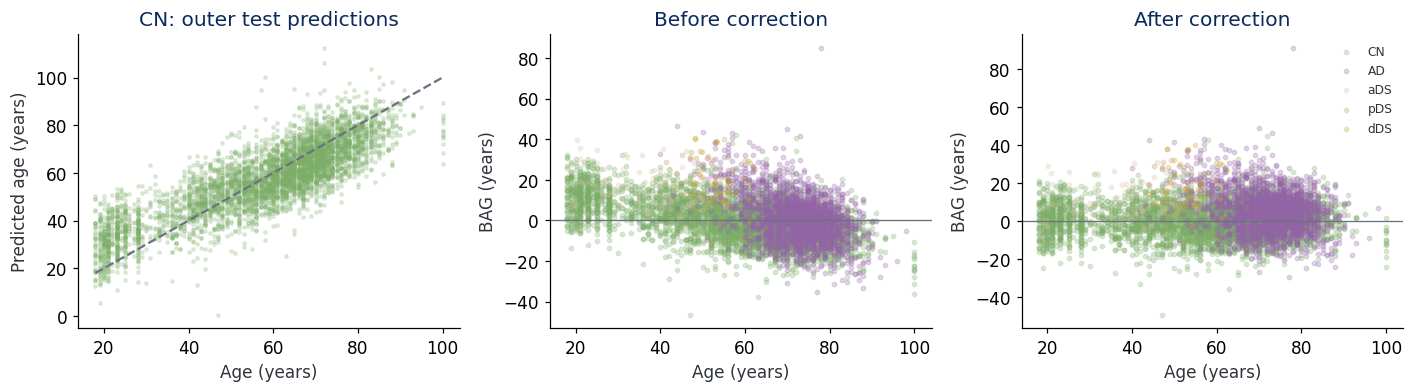

,Group,BAG,r_age,p
0,CN,BAG_raw,-0.5413,0.0000
1,CN,BAG_corrected,-0.0149,0.3052
2,AD,BAG_raw,-0.4315,0.0000
3,AD,BAG_corrected,-0.2539,0.0000
4,aDS,BAG_raw,-0.2455,0.0184
5,aDS,BAG_corrected,0.0713,0.4996
6,pDS,BAG_raw,-0.4894,0.0096
7,pDS,BAG_corrected,-0.4005,0.0385
8,dDS,BAG_raw,-0.2023,0.1933
9,dDS,BAG_corrected,-0.0706,0.6529


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))

cn_results = participant_results.loc[participant_results["Group"] == "CN"]
axes[0].scatter(cn_results["Age"], cn_results["Predicted_age"], s=5, alpha=0.2, color=COLORS["CN"])
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], color="#6B7280", linestyle="--")
axes[0].set(xlabel="Age (years)", ylabel="Predicted age (years)", title="CN: outer test predictions")
correlations = []

for group in GROUPS:
    part = participant_results.loc[participant_results["Group"] == group]
    for ax, column, title in zip(axes[1:], ["BAG_raw", "BAG_corrected"], ["Before correction", "After correction"]):
        ax.scatter(part["Age"], part[column], s=8, alpha=0.25, color=COLORS[group], label=group)
        r, p = pearsonr(part["Age"], part[column])
        correlations.append({"Group": group, "BAG": column, "r_age": r, "p": p})
        ax.set(xlabel="Age (years)", ylabel="BAG (years)", title=title)
        ax.axhline(0, color="#6B7280", linewidth=0.7)
axes[2].legend(frameon=False, fontsize=8)

fig.tight_layout()
plt.show()
display(pd.DataFrame(correlations).round(4))


## Which features help predict age?

**How much worse does age prediction become if we shuffle one ROI across the test participants?**

- Use permutation importance on the held-out CN folds.
- Shuffle one ROI at a time and measure the increase in MAE.
- A positive value means that shuffling that ROI made predictions worse.
- A negative value is possible (e.g., noisy features)


,mean,std
ROI,,
G_Insula_L,1.186057,0.028562
G_Olfactory_R,1.041196,0.025214
G_Insula_R,0.985763,0.017579
G_Cingulum_Mid_L,0.746182,0.016537
G_Caudate_L,0.730082,0.021272
G_Frontal_Sup_Medial_L,0.658723,0.013830
G_Cingulum_Ant_L,0.617635,0.023420
G_ParaHippocampal_L,0.613179,0.019025
G_Temporal_Mid_R,0.540691,0.016739


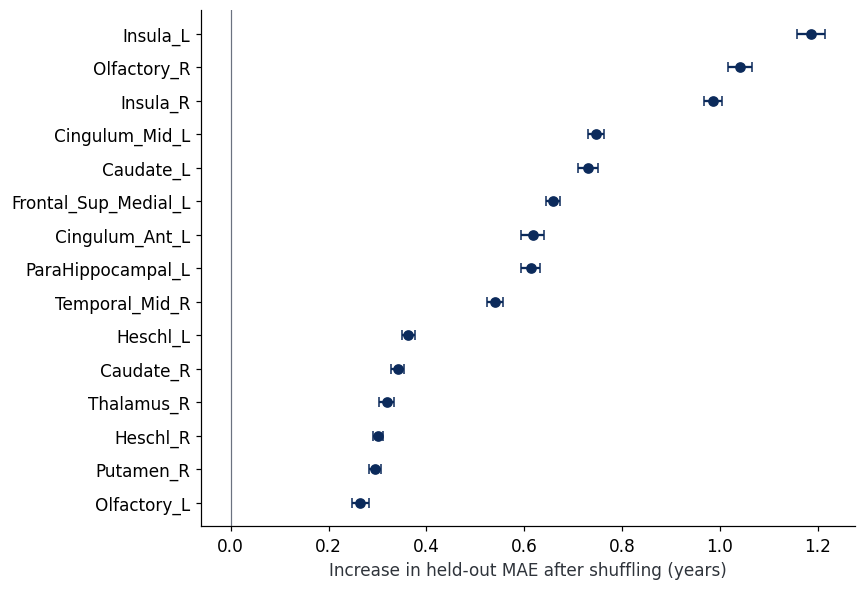

In [7]:
#Feature Importance

importance_rows = [] # for storage (all ROIs, all splits)

# again, CV, splitting data in training and test
for split_id, (train_idx, test_idx) in enumerate(splits):
    
    # same as before
    fitted = clone(pipeline).fit(X[train_idx], y[train_idx])
    
    # permutation_importance evaluates the already fitted model; it does not retrain it
    # Internally, this function:
    # 1. Calculates the original test score.
    # 2. Shuffles one feature column across test participants.
    # 3. Predicts again with the same fitted pipeline.
    # 4. Measures the change in score.
    # 5. Repeats the shuffle five times for that feature.
    # 6. Does this for every ROI.

    # shuffle: completely disorganized the values there.
    
    result = permutation_importance(fitted, X[test_idx], y[test_idx],
                                    scoring="neg_mean_absolute_error", n_repeats=5,
                                    random_state=SEED + split_id, n_jobs=1)

    
    repeat_id, fold_id = divmod(split_id, N_SPLITS) # returns a tuple containing the quotient and the remainder
    for roi, value in zip(rois, result.importances_mean):
        importance_rows.append({"repeat": repeat_id + 1, "fold": fold_id + 1,
                                "ROI": roi, "MAE_increase": value})

# Convert the results into a table, and average across folds within each repetition
importance_folds = pd.DataFrame(importance_rows)
importance_repetitions = importance_folds.groupby(["repeat", "ROI"])["MAE_increase"].mean().reset_index()

# sorting by importance
importance_summary = importance_repetitions.groupby("ROI")["MAE_increase"].agg(["mean", "std"]).sort_values("mean", ascending=False)

display(importance_summary.head(15))
top = importance_summary.head(15).sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.errorbar(top["mean"], np.arange(len(top)), xerr=top["std"], fmt="o", color="#0B2A5B", capsize=3)
ax.set_yticks(np.arange(len(top)), [name[2:] for name in top.index])
ax.axvline(0, color="#6B7280", linewidth=0.8)
ax.set(xlabel="Increase in held-out MAE after shuffling (years)", ylabel="")
fig.tight_layout()
plt.show()


## ANCOVA and group comparisons

- Fit corrected BAG as a function of group and age.
- Use one row per participant and HC3 robust standard errors.
- Compare each group with CN and use Holm correction for these four comparisons.
- Check the age-by-group interaction; a strong interaction questions the common-slope summary.


,sum_sq,df,F,PR(>F)
"C(Group, Treatment(reference='CN'))",54634.110089,4.0,162.952877,1.681558e-133
age_center,1952.640910,1.0,23.295956,1.418773e-06
Residual,578601.721793,6903.0,NaN,NaN


,contrast,difference_years,CI_low,CI_high,p,p_Holm
0,AD - CN,5.6729,5.0985,6.2472,0.0,0.0
1,aDS - CN,9.4820,7.4965,11.4676,0.0,0.0
2,pDS - CN,12.2063,8.1806,16.2319,0.0,0.0
3,dDS - CN,20.6903,17.6242,23.7564,0.0,0.0


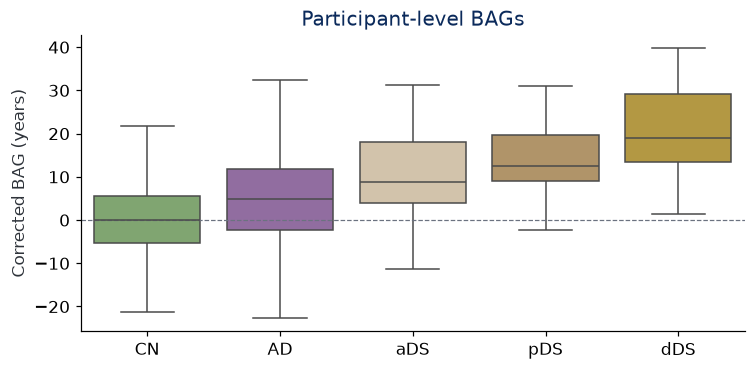

In [7]:
# ANCOVA

# copy of the data with bags, age and groups
analysis = participant_results.copy()
analysis["Group"] = pd.Categorical(analysis["Group"], categories=GROUPS)
analysis["age_center"] = analysis["Age"] - analysis["Age"].mean() # not necessary to be honest

# this is the ANCOVA model
formula = "BAG_corrected ~ age_center + C(Group, Treatment(reference='CN'))"
ancova_model = smf.ols(formula, data=analysis).fit(cov_type="HC3") # fitting the model
display(anova_lm(ancova_model, typ=2, robust="hc3"))

# Find the age range shared by all groups (as we did before in the first notebook)
age_ranges = analysis.groupby("Group", observed=True)["Age"].agg(["min", "max"])
low, high = age_ranges["min"].max(), age_ranges["max"].min()
reference_age = (low + high) / 2
reference_center = reference_age - analysis["Age"].mean()

#Post hocs
comparisons = []
for group in GROUPS[1:]:
    contrast = np.zeros(len(ancova_model.params))
    for j, name in enumerate(ancova_model.params.index):
        if "[T." + group + "]" in name:
            contrast[j] = reference_center if ":" in name else 1
    test = ancova_model.t_test(contrast)
    interval = test.conf_int()[0]

    # store the comparison
    comparisons.append({"contrast": group + " - CN",
                         "difference_years": float(np.asarray(test.effect).item()),
                         "CI_low": interval[0], "CI_high": interval[1],
                         "p": float(np.asarray(test.pvalue).item())})

# make the results a dataframe
comparisons = pd.DataFrame(comparisons)
comparisons["p_Holm"] = multipletests(comparisons["p"], method="holm")[1]
display(comparisons.round(4))

# plotting
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(data=analysis, x="Group", y="BAG_corrected", hue="Group", order=GROUPS, palette=COLORS,
            showfliers=False, dodge=False, legend=False, ax=ax)
ax.axhline(0, color="#6B7280", linestyle="--", linewidth=0.8)
ax.set(xlabel="", ylabel="Corrected BAG (years)", title="Participant-level BAGs")
fig.tight_layout()
plt.show()



## Age prediction versus CN-AD separation

A feature that helps predict age need not help distinguish CN from AD.
We test both outcomes by shuffling one ROI while keeping the fitted model unchanged.

Use the same 5 folds and 10 repetitions. Keep all CN for training and use the shared
CN-AD age range for this comparison. Pool held-out CN and AD, then shuffle within
5-year age bands. This differs from the CN-only permutation importance above.

For each repetition, the CN-AD effect is the group coefficient in
`BAG ~ age + case`, divided by the model residual SD. 


In [8]:
# Set up the AD comparison and its baseline results.
ad_mask = external["Group"].eq("AD").to_numpy()
ad = external.loc[ad_mask].copy()
X_ad = X_external[ad_mask]
age_ad = ad["Age"].to_numpy()
low = max(cn["Age"].min(), ad["Age"].min())
high = min(cn["Age"].max(), ad["Age"].max())
cn_shared = cn["Age"].between(low, high).to_numpy()

print("Comparison ages:", round(low, 1), "to", round(high, 1))
print("CN:", cn_shared.sum(), "AD:", len(ad))

comparison = pd.DataFrame({
    "age": np.r_[y[cn_shared], age_ad],
    "case": np.r_[np.zeros(cn_shared.sum()), np.ones(len(ad))]
})
baseline_effect = []
baseline_mae = []

for repetition in range(N_REPEATS):
    start = repetition * N_SPLITS
    stop = start + N_SPLITS
    comparison["BAG"] = np.r_[
        cn_bag_corrected[repetition, cn_shared],
        external_bag_corrected[start:stop, ad_mask].mean(axis=0)
    ]
    fitted = smf.ols("BAG ~ age + case", data=comparison).fit()
    baseline_effect.append(fitted.params["case"] / np.sqrt(fitted.mse_resid))
    baseline_mae.append(mean_absolute_error(
        y[cn_shared], cn_prediction[repetition, cn_shared]))

print("Baseline CN MAE:", round(np.mean(baseline_mae), 2))
print("Baseline adjusted group effect:", round(np.mean(baseline_effect), 2))


Comparison ages: 40.0 to 98.0
CN: 3891 AD: 2032
Baseline CN MAE: 7.27
Baseline adjusted group effect: 0.61


### Shuffle each ROI and measure both changes

Reuse the models fitted earlier. Do not refit the model or the bias correction after shuffling.
For each ROI, repeat the shuffle five times per fold. Average external predictions
over the five outer models within each repetition, as in the baseline analysis.

- MAE increase = shuffled CN MAE - original CN MAE.
- Effect loss = absolute original group effect - absolute shuffled group effect.




In [9]:
N_SHUFFLES = 5
ad_rows = []

for roi_id, roi in enumerate(rois):
    shuffled_cn_age = np.repeat(cn_prediction[:, None, :], N_SHUFFLES, axis=1)
    shuffled_cn_bag = np.repeat(cn_bag_corrected[:, None, :], N_SHUFFLES, axis=1)
    shuffled_ad_bag = np.zeros((N_REPEATS, N_SHUFFLES, len(ad)))

    for split_id, (_, test_idx) in enumerate(splits):
        repetition, fold = divmod(split_id, N_SPLITS)
        test_idx = test_idx[cn_shared[test_idx]]
        model = models[split_id]
        pool = np.vstack([X[test_idx], X_ad])
        ages = np.r_[y[test_idx], age_ad]
        age_bins = np.floor(ages / 5).astype(int)
        original = np.r_[cn_prediction[repetition, test_idx],
                         external_prediction[split_id, ad_mask]]
        rng = np.random.default_rng(SEED + split_id)

        for shuffle in range(N_SHUFFLES):
            order = np.arange(len(pool))
            for age_bin in np.unique(age_bins):
                members = np.flatnonzero(age_bins == age_bin)
                order[members] = rng.permutation(members)
            shuffled = pool.copy()
            shuffled[:, roi_id] = pool[order, roi_id]
            predicted = model.predict(shuffled)
            change = predicted - original
            n_test = len(test_idx)
            shuffled_cn_age[repetition, shuffle, test_idx] = predicted[:n_test]
            shuffled_cn_bag[repetition, shuffle, test_idx] += change[:n_test]
            shuffled_ad_bag[repetition, shuffle] += (
                external_bag_corrected[split_id, ad_mask] + change[n_test:]
            ) / N_SPLITS

    for repetition in range(N_REPEATS):
        for shuffle in range(N_SHUFFLES):
            mae = mean_absolute_error(
                y[cn_shared], shuffled_cn_age[repetition, shuffle, cn_shared])
            comparison["BAG"] = np.r_[
                shuffled_cn_bag[repetition, shuffle, cn_shared],
                shuffled_ad_bag[repetition, shuffle]
            ]
            fitted = smf.ols("BAG ~ age + case", data=comparison).fit()
            effect = fitted.params["case"] / np.sqrt(fitted.mse_resid)
            ad_rows.append({
                "ROI": roi, "repeat": repetition + 1,
                "MAE_increase": mae - baseline_mae[repetition],
                "effect_loss": abs(baseline_effect[repetition]) - abs(effect)
            })

    if (roi_id + 1) % 15 == 0:
        print("Completed", roi_id + 1, "of", len(rois), "ROIs")

ad_permutations = pd.DataFrame(ad_rows)
ad_repetitions = ad_permutations.groupby(["repeat", "ROI"])[
    ["MAE_increase", "effect_loss"]].mean()
ad_importance = ad_repetitions.groupby("ROI").mean()


Completed 15 of 90 ROIs
Completed 30 of 90 ROIs
Completed 45 of 90 ROIs
Completed 60 of 90 ROIs
Completed 75 of 90 ROIs
Completed 90 of 90 ROIs


Completed 45 of 90 ROIs


Completed 60 of 90 ROIs


Completed 75 of 90 ROIs


Completed 90 of 90 ROIs


### Compare feature importance for the two outcomes

Each point is one ROI. Further right means more useful for age prediction under this
permutation experiment; higher means more useful for preserving CN-AD separation.
The correlation is descriptive: ROIs are correlated, and this is one fixed model.
Group separation is not classification accuracy or clinical diagnostic performance.


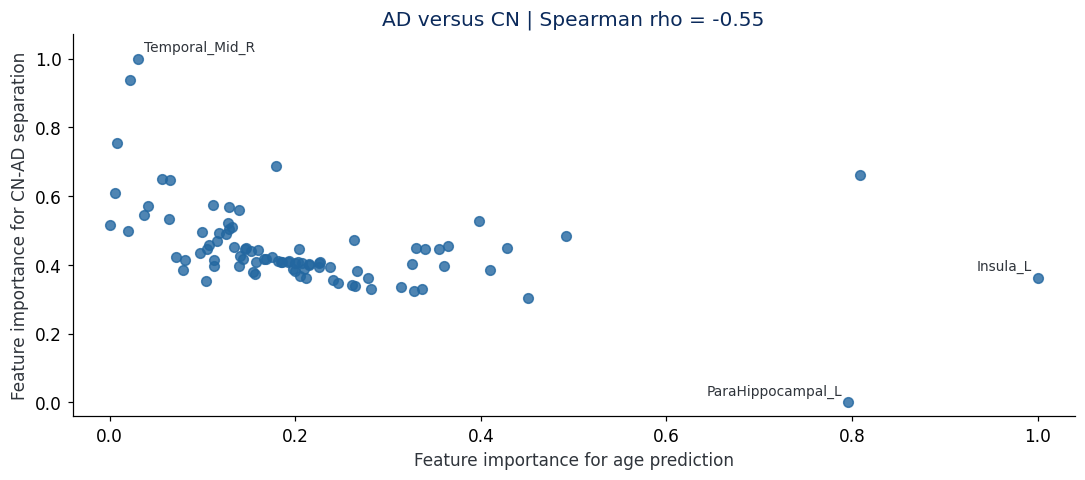

In [13]:
from scipy.stats import spearmanr

raw_importance = ad_importance[["MAE_increase", "effect_loss"]]
# Rescale each axis separately to 0-1; this preserves the Spearman correlation.
feature_importance = (raw_importance - raw_importance.min()) / (
    raw_importance.max() - raw_importance.min())
rho = spearmanr(raw_importance["MAE_increase"], raw_importance["effect_loss"]).statistic

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(feature_importance["MAE_increase"], feature_importance["effect_loss"],
           s=40, color="#2367A0", alpha=0.8)
for roi in ["G_Insula_L", "G_Temporal_Mid_R", "G_ParaHippocampal_L"]:
    x, y_plot = feature_importance.loc[roi]
    ax.annotate(roi[2:], (x, y_plot), xytext=(-4 if x > 0.7 else 4, 5),
                ha="right" if x > 0.7 else "left",
                textcoords="offset points", fontsize=9)
ax.set(xlim=(-0.04, 1.04), ylim=(-0.04, 1.07),
       xticks=np.linspace(0, 1, 6), yticks=np.linspace(0, 1, 6),
       xlabel="Feature importance for age prediction",
       ylabel="Feature importance for CN-AD separation",
       title="AD versus CN | Spearman rho = " + str(round(rho, 2)))
fig.tight_layout()

plt.show()


### Delta expansion

In this example, importance for age prediction and importance for CN-AD separation
are negatively associated.

Delta expansion refers to increasing between-person spread around an age-related
trajectory. A prediction model may downweight features that vary substantially
between people of the same age. 
